<a href="https://colab.research.google.com/github/suciii12309-hub/INI-JUGA/blob/main/Tgs_Kecerdasan_Buatan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Perhitungan Matematis Scaled Dot-Product Attention
Mekanisme Scaled Dot-Product Attention digunakan untuk menghitung tingkat keterkaitan antara Query (Q), Key (K), dan Value (V). Pada simulasi ini, ketiga matriks menggunakan nilai yang sama dengan dimensi \(d_k=2\), yaitu:
\[
Q=K=V=
\begin{bmatrix}
1&0\\
0&1\\
1&1
\end{bmatrix}
\]

Tahapan perhitungannya adalah sebagai berikut.
1. Matriks Query dikalikan dengan transpose matriks Key (\(K^T\)) untuk memperoleh skor kesamaan antarvektor.
2. Hasil perkalian dibagi dengan akar dimensi Key, yaitu \(\sqrt{d_k}=\sqrt{2}\), agar nilai skor lebih terkendali.
3. Fungsi Softmax diterapkan pada setiap baris untuk mengubah skor menjadi distribusi bobot perhatian.
4. Bobot perhatian dikalikan dengan matriks Value untuk menghasilkan keluaran Attention.
Hasil perhitungan menunjukkan bahwa setiap elemen dapat memberikan perhatian dengan proporsi yang berbeda terhadap elemen lainnya. Nilai Attention yang diperoleh menjadi representasi informasi yang telah mempertimbangkan hubungan antarelemen dalam urutan data.

2. Pengamatan Matriks Masking Segitiga Bawah (Causal Mask)
Causal Mask berfungsi membatasi perhatian model agar suatu token hanya dapat mengakses token sebelumnya dan token pada posisinya sendiri. Mekanisme ini digunakan untuk menjaga urutan pemrosesan informasi, terutama dalam tugas prediksi teks secara berurutan.
Pada simulasi ini, token yang berada di masa depan ditutupi menggunakan nilai negatif tak hingga sebelum proses Softmax dilakukan. Akibatnya, bobot perhatian pada posisi tersebut menjadi nol. Matriks yang dihasilkan berbentuk segitiga bawah, karena hanya posisi yang diizinkan yang dapat berkontribusi terhadap perhitungan Attention.
Penerapan Causal Mask memastikan bahwa token yang sedang diproses tidak memperoleh informasi dari token yang belum seharusnya diketahui. Hal ini membuat proses prediksi tetap mengikuti urutan data yang benar.

3. Sebaran Bobot Perhatian (Attention Heatmap)
Visualisasi Attention Heatmap digunakan untuk memperlihatkan distribusi bobot perhatian antarkata dalam sebuah kalimat. Pada contoh kalimat “Mahasiswa sedang belajar kecerdasan buatan di kampus”, setiap baris menunjukkan token yang memberikan perhatian, sedangkan setiap kolom menunjukkan token yang menjadi sasaran perhatian.
Warna yang lebih terang menggambarkan bobot perhatian yang relatif tinggi, sedangkan warna yang lebih gelap menunjukkan bobot yang lebih rendah. Perbedaan intensitas warna tersebut memperlihatkan bahwa setiap token memiliki tingkat keterkaitan yang berbeda dengan token lainnya.
Heatmap membantu mengidentifikasi pola hubungan antarkata yang dipelajari model. Akan tetapi, bobot Attention tidak selalu dapat diartikan sebagai ukuran kepentingan semantik secara langsung; interpretasinya perlu mempertimbangkan konteks dan mekanisme model yang digunakan.

1. Hasil Q @ K.T:
[[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]

2. Hasil Q @ K.T / sqrt(dk):
[[0.707 0.    0.707]
 [0.    0.707 0.707]
 [0.707 0.707 1.414]]

3. Bobot perhatian setelah Softmax:
[[0.401 0.198 0.401]
 [0.198 0.401 0.401]
 [0.248 0.248 0.503]]

4. Output Attention:
[[0.802 0.599]
 [0.599 0.802]
 [0.752 0.752]]

Matriks Causal Mask:
[[0 1 1 1 1]
 [0 0 1 1 1]
 [0 0 0 1 1]
 [0 0 0 0 1]
 [0 0 0 0 0]]

Skor setelah Causal Mask:
[[ 1.  -inf -inf -inf -inf]
 [ 0.8  1.  -inf -inf -inf]
 [ 0.6  0.7  1.  -inf -inf]
 [ 0.4  0.5  0.8  1.  -inf]
 [ 0.2  0.3  0.4  0.7  1. ]]

Bobot perhatian setelah Causal Mask:
[[1.    0.    0.    0.    0.   ]
 [0.45  0.55  0.    0.    0.   ]
 [0.278 0.307 0.415 0.    0.   ]
 [0.185 0.204 0.275 0.336 0.   ]
 [0.139 0.153 0.17  0.229 0.309]]


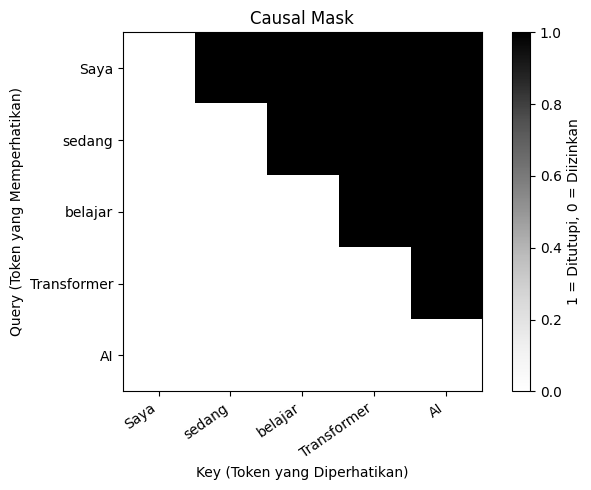


Matriks bobot Attention Heatmap:
[[0.063 0.101 0.083 0.198 0.219 0.128 0.209]
 [0.292 0.075 0.25  0.129 0.033 0.084 0.137]
 [0.183 0.143 0.137 0.045 0.229 0.147 0.117]
 [0.177 0.037 0.227 0.213 0.019 0.066 0.261]
 [0.233 0.172 0.148 0.191 0.078 0.103 0.075]
 [0.208 0.073 0.176 0.247 0.043 0.09  0.163]
 [0.121 0.17  0.105 0.068 0.287 0.128 0.12 ]]


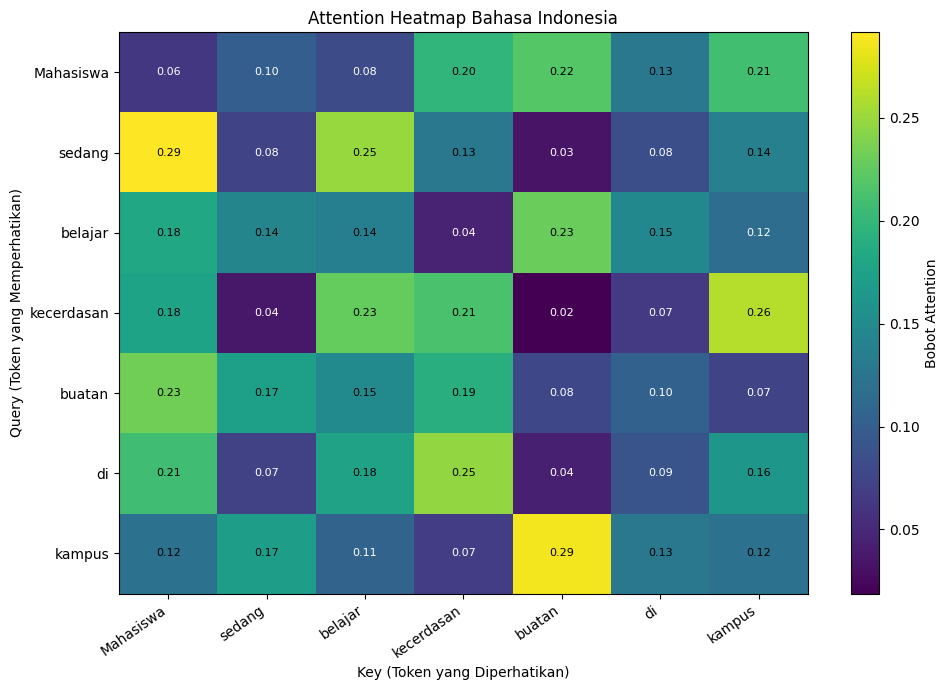

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. SCALED DOT-PRODUCT ATTENTION
# ==========================================

np.set_printoptions(precision=3, suppress=True)

Q = np.array([
    [1, 0],
    [0, 1],
    [1, 1]
], dtype=float)

K = Q.copy()
V = Q.copy()

dk = K.shape[1]

# Menghitung skor perhatian
scores = Q @ K.T

print("1. Hasil Q @ K.T:")
print(scores)

# Skala skor perhatian
scaled_scores = scores / np.sqrt(dk)

print("\n2. Hasil Q @ K.T / sqrt(dk):")
print(scaled_scores)

# Fungsi Softmax
def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

attention_weights = softmax(scaled_scores)

print("\n3. Bobot perhatian setelah Softmax:")
print(attention_weights)

# Menghasilkan keluaran Attention
attention_output = attention_weights @ V

print("\n4. Output Attention:")
print(attention_output)


# ==========================================
# 2. CAUSAL MASK
# ==========================================

tokens = ["Saya", "sedang", "belajar",
          "Transformer", "AI"]

# Menggunakan matriks skor untuk simulasi
causal_scores = np.array([
    [1.00, 0.80, 0.60, 0.40, 0.20],
    [0.80, 1.00, 0.70, 0.50, 0.30],
    [0.60, 0.70, 1.00, 0.80, 0.40],
    [0.40, 0.50, 0.80, 1.00, 0.70],
    [0.20, 0.30, 0.40, 0.70, 1.00]
])

# Mask segitiga atas: token masa depan dilarang
mask = np.triu(
    np.ones(causal_scores.shape, dtype=bool),
    k=1
)

masked_scores = np.where(mask, -np.inf, causal_scores)

# Softmax setelah masking
causal_weights = np.zeros_like(masked_scores)

for i in range(len(tokens)):
    causal_weights[i] = softmax(masked_scores[i])

print("\nMatriks Causal Mask:")
print(mask.astype(int))

print("\nSkor setelah Causal Mask:")
print(masked_scores)

print("\nBobot perhatian setelah Causal Mask:")
print(causal_weights)

# Visualisasi Causal Mask
plt.figure(figsize=(7, 5))
plt.imshow(mask.astype(int), cmap="Greys", vmin=0, vmax=1)
plt.xticks(range(len(tokens)), tokens, rotation=35, ha="right")
plt.yticks(range(len(tokens)), tokens)
plt.title("Causal Mask")
plt.xlabel("Key (Token yang Diperhatikan)")
plt.ylabel("Query (Token yang Memperhatikan)")
plt.colorbar(label="1 = Ditutupi, 0 = Diizinkan")
plt.tight_layout()
plt.show()


# ==========================================
# 3. ATTENTION HEATMAP
# ==========================================

words = [
    "Mahasiswa", "sedang", "belajar",
    "kecerdasan", "buatan", "di", "kampus"
]

# Representasi vektor sederhana untuk simulasi
np.random.seed(42)
X = np.random.randn(len(words), 8)

# Matriks proyeksi Q dan K
WQ = np.random.randn(8, 8) / np.sqrt(8)
WK = np.random.randn(8, 8) / np.sqrt(8)

Q_heat = X @ WQ
K_heat = X @ WK

# Skor dan bobot perhatian
heat_scores = Q_heat @ K_heat.T / np.sqrt(8)
heat_weights = softmax(heat_scores)

print("\nMatriks bobot Attention Heatmap:")
print(heat_weights)

# Visualisasi Heatmap
plt.figure(figsize=(10, 7))

plt.imshow(
    heat_weights,
    cmap="viridis",
    aspect="auto"
)

plt.xticks(
    range(len(words)),
    words,
    rotation=35,
    ha="right"
)

plt.yticks(range(len(words)), words)

plt.title("Attention Heatmap Bahasa Indonesia")
plt.xlabel("Key (Token yang Diperhatikan)")
plt.ylabel("Query (Token yang Memperhatikan)")

plt.colorbar(label="Bobot Attention")

# Menampilkan nilai di setiap sel
for i in range(len(words)):
    for j in range(len(words)):
        plt.text(
            j, i,
            f"{heat_weights[i, j]:.2f}",
            ha="center",
            va="center",
            color="white" if heat_weights[i, j] < 0.12
            else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()
